In [15]:
from pathlib import Path
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import seaborn as sns

import ipywidgets as widgets
from IPython.display import display

import torch
# from segment_anything import sam_model_registry, SamAutomaticMaskGenerator

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Device
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# Project paths
PROJECT_ROOT = Path.cwd().parent  # If notebook is in notebooks/
DATA_DIR = PROJECT_ROOT / "data"
MODEL_PATH = PROJECT_ROOT / "models" / "sam_vit_b_01ec64.pth"

Using device: cpu


In [ ]:
df = pd.read_csv(DATA_DIR / "final_data.csv")

Index(['dataset', 'lesion_id', 'image_id', 'age', 'sex', 'skin_tone_class',
       'diagnosis_confirm_type', 'AKIEC', 'BCC', 'BEN_OTH', 'BKL', 'DF', 'INF',
       'MAL_OTH', 'MEL', 'NV', 'SCCKA', 'VASC', 'path', 'path_segmentation'],
      dtype='str')

In [ ]:
def explore_images(df, data_dir=DATA_DIR):
    """
    Interactive image explorer for the skin lesion dataset.

    Filters:
        dataset
        age
        sex
        skin_tone_class
        diagnosis_confirm_type

    Additionally, select one of the 11 diagnoses.
    Only images with the selected diagnosis == 1 are shown.
    """

    from IPython.display import display, clear_output

    categories = ["AKIEC", "BCC", "BEN_OTH", "BKL", "DF", "INF", "MAL_OTH", "MEL", "NV", "SCCKA", "VASC"]

    # Create dropdown options, including an "All" option
    def get_options(column):
        values = df[column].dropna().unique().tolist()
        values = sorted(values, key=str)
        return [("All", None)] + [(str(v), v) for v in values]

    # Filters
    dataset = widgets.Dropdown(options=get_options("dataset"), description="Dataset:")

    age = widgets.Dropdown(options=get_options("age"), description="Age:")

    sex = widgets.Dropdown(options=get_options("sex"), description="Sex:")

    skin_tone = widgets.Dropdown(options=get_options("skin_tone_class"), description="Skin tone:")

    confirm_type = widgets.Dropdown(options=get_options("diagnosis_confirm_type"), description="Confirm type:")

    diagnosis = widgets.Dropdown(options=categories, value="MEL", description="Diagnosis:")

    n_images = widgets.IntSlider(value=10, min=1, max=50, step=1, description="Images:")

    # Output area
    output = widgets.Output()

    def update_images(*args):

        with output:
            clear_output(wait=True)

            filtered = df.copy()

            # Apply filters
            filters = {
                "dataset": dataset.value,
                "age": age.value,
                "sex": sex.value,
                "skin_tone_class": skin_tone.value,
                "diagnosis_confirm_type": confirm_type.value,
            }

            for column, value in filters.items():
                if value is not None:
                    filtered = filtered[filtered[column] == value]

            # Filter by selected diagnosis
            filtered = filtered[filtered[diagnosis.value] == 1]

            print(f"Matching images: {len(filtered)}")

            if filtered.empty:
                print("No images match the selected filters.")
                return

            # Randomly sample images
            sample = filtered.sample(n=min(n_images.value, len(filtered)))

            # Display images in a 5-column grid
            sample = filtered.sample(n=min(n_images.value, len(filtered)))

            image_widgets = []

            for _, row in sample.iterrows():
                img_path = Path(row["path"])

                if not img_path.is_absolute():
                    img_path = Path(data_dir) / img_path

                if img_path.exists():
                    img = Image.open(img_path)
                    img.thumbnail((150, 150))

                    image_widgets.append(
                        widgets.VBox(
                            [
                                widgets.HTML(f"<b>{row['image_id']}</b><br>{row['dataset']} | Age: {row['age']}"),
                                widgets.Image(value=img.convert("RGB")._repr_png_(), format="png", width=150, height=150),
                            ]
                        )
                    )

                else:
                    image_widgets.append(widgets.HTML(f"Image not found: {img_path}"))

            # Arrange in rows of five
            grid = widgets.GridBox(image_widgets, layout=widgets.Layout(grid_template_columns="repeat(5, 160px)", grid_gap="10px"))

            display(grid)

    # Update whenever a filter changes
    controls = [dataset, age, sex, skin_tone, confirm_type, diagnosis, n_images]

    for control in controls:
        control.observe(update_images, names="value")

    # Initial display
    display(
        widgets.VBox(
            [
                widgets.HTML("<h3>Skin Lesion Image Explorer</h3>"),
                widgets.HBox([dataset, age]),
                widgets.HBox([sex, skin_tone]),
                widgets.HBox([confirm_type, diagnosis]),
                n_images,
                output,
            ]
        )
    )

    update_images()


In [ ]:
explore_images(df)

Check data

In [ ]:
from pathlib import Path
import pandas as pd


# --------------------------------------------------
# Paths
# --------------------------------------------------

# PROJECT_ROOT = Path(__file__).resolve().parent.parent
DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_PATH = DATA_DIR / "final_data.csv"


# --------------------------------------------------
# Load data
# --------------------------------------------------

# MILK10k
df_milk_truth = pd.read_csv(DATA_DIR / "MILK10k_Training_GroundTruth.csv")
df_milk_meta = pd.read_csv(DATA_DIR / "MILK10k_Training_Metadata.csv")
df_milk_supplement = pd.read_csv(DATA_DIR / "MILK10k_Training_Supplement.csv")

df_milk = df_milk_meta.merge(df_milk_truth, on="lesion_id", how="left", validate="many_to_one")

# ISIC 2017
df_isic_truth = pd.read_csv(DATA_DIR / "ISIC-2017_Training_Part3_GroundTruth.csv")
df_isic_meta = pd.read_csv(DATA_DIR / "ISIC-2017_Training_Data" / "ISIC-2017_Training_Data_metadata.csv")

df_isic = df_isic_meta.merge(df_isic_truth, on="image_id", how="left", validate="many_to_one")


# --------------------------------------------------
# Define diagnosis categories
# --------------------------------------------------

categories = ["AKIEC", "BCC", "BEN_OTH", "BKL", "DF", "INF", "MAL_OTH", "MEL", "NV", "SCCKA", "VASC"]

# --------------------------------------------------
# Add diagnosis type
# --------------------------------------------------

df_milk = df_milk.merge(df_milk_supplement[["isic_id", "diagnosis_confirm_type"]], on="isic_id", how="left", validate="many_to_one")

# --------------------------------------------------
# Preprocess MILK10k
# --------------------------------------------------

df_milk["age"] = df_milk["age_approx"]
df_milk["image_id"] = df_milk["isic_id"]

df_milk["path"] = df_milk.apply(lambda row: Path("MILK10k_Training_Input") / row["lesion_id"] / f"{row['isic_id']}.jpg", axis=1)

# MILK10k has no segmentation masks
df_milk["path_segmentation"] = pd.NA

# Add dataset indicator
df_milk["dataset"] = "MILK10k"

# Keep relevant columns
milk_columns = [
    "dataset",
    "lesion_id",
    "image_id",
    "image_type",
    "age",
    "sex",
    "skin_tone_class",
    "diagnosis_confirm_type",
    *categories,
    "path",
    "path_segmentation",
]

df_milk = df_milk[milk_columns]


# --------------------------------------------------
# Preprocess ISIC 2017
# --------------------------------------------------

df_isic["age"] = df_isic["age_approximate"]
df_isic["skin_tone_class"] = pd.NA
df_isic["image_type"] = pd.NA
df_isic["diagnosis_confirm_type"] = pd.NA

df_isic["path"] = df_isic["image_id"].apply(lambda x: Path("ISIC-2017_Training_resizedImages") / f"{x}.jpg")

df_isic["path_segmentation"] = df_isic["image_id"].apply(lambda x: Path("ISIC-2017_Training_resizedSegmentation") / f"{x}_segmentation.png")

df_isic = df_isic.rename(columns={"melanoma": "MEL"})
df_isic["NV"] = ((df_isic["MEL"] == 0) & (df_isic["seborrheic_keratosis"] == 0)).astype(float)

# Create other diagnoses
for category in categories:
    if category not in ["MEL", "NV"]:
        df_isic[category] = 0

# exclude seborrheic_keratosis
df_isic = df_isic.loc[(df_isic["NV"] != 0) | (df_isic["MEL"] != 0)].copy()

df_isic["dataset"] = "ISIC2017"
df_isic["lesion_id"] = pd.NA

# Keep relevant columns
isic_columns = [
    "dataset",
    "lesion_id",
    "image_id",
    "image_type",
    "age",
    "sex",
    "skin_tone_class",
    "diagnosis_confirm_type",
    *categories,
    "path",
    "path_segmentation",
]


# df_isic = df_isic[isic_columns]
df_isic


,image_id,age_approximate,sex,MEL,seborrheic_keratosis,age,skin_tone_class,image_type,diagnosis_confirm_type,path,path_segmentation,NV,dataset,lesion_id
0,ISIC_0000000,55,female,0.0,0.0,55,<NA>,<NA>,<NA>,ISIC-2017_Training_resizedImages\ISIC_0000000.jpg,ISIC-2017_Training_resizedSegmentation\ISIC_00...,1.0,ISIC2017,<NA>
1,ISIC_0000001,30,female,0.0,0.0,30,<NA>,<NA>,<NA>,ISIC-2017_Training_resizedImages\ISIC_0000001.jpg,ISIC-2017_Training_resizedSegmentation\ISIC_00...,1.0,ISIC2017,<NA>
2,ISIC_0000002,60,female,1.0,0.0,60,<NA>,<NA>,<NA>,ISIC-2017_Training_resizedImages\ISIC_0000002.jpg,ISIC-2017_Training_resizedSegmentation\ISIC_00...,0.0,ISIC2017,<NA>
3,ISIC_0000003,30,male,0.0,0.0,30,<NA>,<NA>,<NA>,ISIC-2017_Training_resizedImages\ISIC_0000003.jpg,ISIC-2017_Training_resizedSegmentation\ISIC_00...,1.0,ISIC2017,<NA>
4,ISIC_0000004,80,male,1.0,0.0,80,<NA>,<NA>,<NA>,ISIC-2017_Training_resizedImages\ISIC_0000004.jpg,ISIC-2017_Training_resizedSegmentation\ISIC_00...,0.0,ISIC2017,<NA>
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1991,ISIC_0015190,80,male,1.0,0.0,80,<NA>,<NA>,<NA>,ISIC-2017_Training_resizedImages\ISIC_0015190.jpg,ISIC-2017_Training_resizedSegmentation\ISIC_00...,0.0,ISIC2017,<NA>
1992,ISIC_0015200,unknown,unknown,1.0,0.0,unknown,<NA>,<NA>,<NA>,ISIC-2017_Training_resizedImages\ISIC_0015200.jpg,ISIC-2017_Training_resizedSegmentation\ISIC_00...,0.0,ISIC2017,<NA>
1993,ISIC_0015204,30,male,1.0,0.0,30,<NA>,<NA>,<NA>,ISIC-2017_Training_resizedImages\ISIC_0015204.jpg,ISIC-2017_Training_resizedSegmentation\ISIC_00...,0.0,ISIC2017,<NA>
1994,ISIC_0015219,unknown,male,1.0,0.0,unknown,<NA>,<NA>,<NA>,ISIC-2017_Training_resizedImages\ISIC_0015219.jpg,ISIC-2017_Training_resizedSegmentation\ISIC_00...,0.0,ISIC2017,<NA>


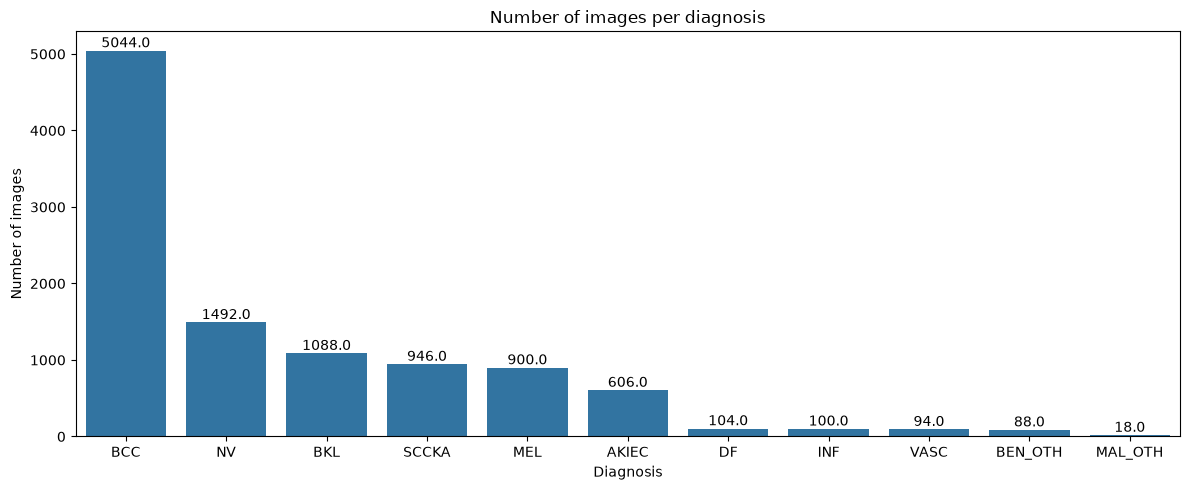

In [ ]:
diagnoses = ["AKIEC", "BCC", "BEN_OTH", "BKL", "DF", "INF", "MAL_OTH", "MEL", "NV", "SCCKA", "VASC"]

counts = df_milk[diagnoses].sum().sort_values(ascending=False)

plt.figure(figsize=(12, 5))
sns.barplot(x=counts.index, y=counts.values)

plt.xlabel("Diagnosis")
plt.ylabel("Number of images")
plt.title("Number of images per diagnosis")

for i, count in enumerate(counts.values):
    plt.text(i, count, str(count), ha="center", va="bottom")

plt.tight_layout()
plt.show()

Use ISIC-2017 data because they come with segmentation masks

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(18, 8))

for ax, path in zip(axes.flat, df_milk[df_milk["MEL"] == 1].path):
    image = load_image(DATA_DIR / path)

    ax.imshow(image)
    ax.set_title(path.name)
    ax.axis("off")

plt.tight_layout()
plt.show()